# Лабораторна робота № 6

**Тема:** Нейронна регресія для табличних даних у TensorFlow  
**Студент:** Люлько Станіслав  
**Номер у списку:** 17  
**Варіант:** $v=(17-1)\bmod 10+1=7$  
**Зміна варіанта:** `learning_rate=0.003` замість `0.001`.


## Мета

Підготувати реальні табличні дані без витоку інформації, порівняти нейромережі з класичними моделями, обирати модель за валідаційною вибіркою, проаналізувати помилки та зберегти повний процес прогнозування.

## 1. Дані та середовище

Використано **UCI Auto MPG** (DOI: [10.24432/C5859H](https://doi.org/10.24432/C5859H)), ліцензія **CC BY 4.0**. Ціль `mpg` вимірюється в милях на галон; більше значення означає вищу паливну ефективність. Локальна копія `auto-mpg.data` отримана з офіційного архіву UCI. Файл `auto-mpg.data-original` не використовується.

> Примітка щодо відтворення: TensorFlow 2.16.2 є останньою версією з wheel для Intel macOS і потребує Python 3.12. Код нижче є звичайним TensorFlow/Keras-кодом і також працює з новішим сумісним TensorFlow на інших платформах.

In [1]:
import json
import platform
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

tf.get_logger().setLevel("ERROR")

SEED = 42
STUDENT_NUMBER = 17
VARIANT = (STUDENT_NUMBER - 1) % 10 + 1
keras.utils.set_random_seed(SEED)

# Обмежуємо кількість потоків для відтворюваного CPU-виконання.
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.threading.set_intra_op_parallelism_threads(1)

data_path = Path("auto-mpg.data")
if not data_path.exists():
    data_path = Path("Lab6") / "auto-mpg.data"
output_dir = data_path.parent.resolve()

versions = {
    "python": platform.python_version(),
    "tensorflow": tf.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "matplotlib": plt.matplotlib.__version__,
    "joblib": joblib.__version__,
}

print(f"SEED={SEED}; номер у списку={STUDENT_NUMBER}; варіант={VARIANT}")
print("Робоча папка артефактів:", output_dir)
pd.Series(versions, name="version").to_frame()

SEED=42; номер у списку=17; варіант=7
Робоча папка артефактів: /Users/staslulko/Documents/GitHub/data-mining/Lab6


,version
python,3.12.14
tensorflow,2.16.2
numpy,1.26.4
pandas,3.0.6
scikit_learn,1.9.1
matplotlib,3.11.2
joblib,1.6.0


In [2]:
columns = [
    "mpg", "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin", "car_name",
]

df = pd.read_csv(data_path, sep=r"\s+", names=columns, na_values="?")
X = df.drop(columns=["mpg", "car_name"])
y = df["mpg"].astype(np.float32)

display(df.head())
print("Форма таблиці:", df.shape)
print("\nТипи даних:")
display(df.dtypes.to_frame("dtype"))
print("Пропуски за стовпцями:")
display(df.isna().sum().to_frame("missing"))
print("Кількість повністю дубльованих рядків:", int(df.duplicated().sum()))
print("Дублікати автоматично не видаляються: спочатку треба довести, що це помилки даних.")

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


Форма таблиці: (398, 9)

Типи даних:


,dtype
mpg,float64
cylinders,int64
displacement,float64
horsepower,float64
weight,float64
acceleration,float64
model_year,int64
origin,int64
car_name,str


Пропуски за стовпцями:


,missing
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
car_name,0


Кількість повністю дубльованих рядків: 0
Дублікати автоматично не видаляються: спочатку треба довести, що це помилки даних.


## 2. Спільний поділ і препроцесинг

Спочатку виконується поділ приблизно 70/15/15. Імпутер, кодування категорії та всі статистики навчаються **лише на train**. `origin` кодується як категорія, оскільки числа 1, 2 і 3 є позначеннями регіонів, а не кількісною шкалою.

In [3]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.15 / 0.85, random_state=SEED
)

split_sizes = pd.Series(
    {"train": len(X_train), "validation": len(X_val), "test": len(X_test)},
    name="rows",
)
display(split_sizes.to_frame())

train_idx, val_idx, test_idx = set(X_train.index), set(X_val.index), set(X_test.index)
overlaps = {
    "train ∩ validation": len(train_idx & val_idx),
    "train ∩ test": len(train_idx & test_idx),
    "validation ∩ test": len(val_idx & test_idx),
}
print("Перетини індексів:", overlaps)
assert sum(overlaps.values()) == 0
assert len(X_train) + len(X_val) + len(X_test) == len(X)

,rows
train,278
validation,60
test,60


Перетини індексів: {'train ∩ validation': 0, 'train ∩ test': 0, 'validation ∩ test': 0}


In [4]:
numeric_features = [
    "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year",
]
categorical_features = ["origin"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

X_train_ready = preprocessor.fit_transform(X_train).astype(np.float32)
X_val_ready = preprocessor.transform(X_val).astype(np.float32)
X_test_ready = preprocessor.transform(X_test).astype(np.float32)
feature_names = preprocessor.get_feature_names_out().tolist()

prepared_shapes = pd.DataFrame(
    [X_train_ready.shape, X_val_ready.shape, X_test_ready.shape],
    index=["train", "validation", "test"],
    columns=["rows", "features"],
)
display(prepared_shapes)
display(pd.Series(feature_names, name="prepared_feature"))

for name, values in {
    "train": X_train_ready, "validation": X_val_ready, "test": X_test_ready
}.items():
    assert np.isfinite(values).all(), f"{name} містить NaN або нескінченні значення"
print("Після препроцесингу NaN та нескінченні значення відсутні.")

,rows,features
train,278,9
validation,60,9
test,60,9


0       num__cylinders
1    num__displacement
2      num__horsepower
3          num__weight
4    num__acceleration
5      num__model_year
6        cat__origin_1
7        cat__origin_2
8        cat__origin_3
Name: prepared_feature, dtype: str

Після препроцесингу NaN та нескінченні значення відсутні.


## 3. Класичні базові моделі

`DummyRegressor` показує якість постійного прогнозу середнім значенням, а лінійна регресія є сильною простою точкою порівняння. На цьому етапі test не використовується.

In [5]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }


dummy_model = DummyRegressor(strategy="mean")
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression()),
])

dummy_model.fit(X_train_ready, y_train)
linear_model.fit(X_train_ready, y_train)

classical_models = {
    "DummyRegressor": dummy_model,
    "LinearRegression": linear_model,
}
classical_val_metrics = {
    name: regression_metrics(y_val, model.predict(X_val_ready))
    for name, model in classical_models.items()
}
display(pd.DataFrame(classical_val_metrics).T.round(4))

,MAE,RMSE,R2
DummyRegressor,7.3549,8.6119,-0.0000
LinearRegression,2.9013,3.6103,0.8242


## 4. Базова нейромережа та варіант 7

Обидві мережі мають `Normalization`, два шари `Dense(32, relu)` та вихідний `Dense(1)` без активації. Відмінність варіанта 7 — лише `learning_rate=0.003`. Для кожного експерименту створюється нова мережа та повторно встановлюється seed.

In [6]:
def build_model(learning_rate, name):
    keras.utils.set_random_seed(SEED)
    normalizer = layers.Normalization(axis=-1, name="normalization")
    normalizer.adapt(X_train_ready)  # лише train
    model = keras.Sequential([
        layers.Input(shape=(X_train_ready.shape[1],)),
        normalizer,
        layers.Dense(32, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1),
    ], name=name)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mse",
        metrics=["mae"],
    )
    return model


baseline_model = build_model(learning_rate=0.001, name="baseline_network")
variant_model = build_model(learning_rate=0.003, name="variant_7_network")

print("Базова мережа")
baseline_model.summary()
print("\nМережа варіанта 7")
variant_model.summary()

Базова мережа


Model: "baseline_network"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,428 (5.58 KB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 19 (80.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,428 (5.58 KB)

 Trainable params: 1,409 (5.50 KB)

 Non-trainable params: 19 (80.00 B)

In [7]:
def train_with_checkpoint(model, checkpoint_name, batch_size=32):
    checkpoint_path = output_dir / checkpoint_name
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", mode="min", patience=20,
            restore_best_weights=True,
        ),
        keras.callbacks.ModelCheckpoint(
            checkpoint_path, monitor="val_loss", mode="min",
            save_best_only=True,
        ),
    ]
    history = model.fit(
        X_train_ready,
        y_train.to_numpy().reshape(-1, 1),
        validation_data=(X_val_ready, y_val.to_numpy().reshape(-1, 1)),
        epochs=400,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=0,
        shuffle=True,
    )
    best_model = keras.models.load_model(checkpoint_path)
    details = {
        "epochs": len(history.history["loss"]),
        "best_epoch": int(np.argmin(history.history["val_loss"]) + 1),
        "best_val_loss": float(np.min(history.history["val_loss"])),
    }
    return history, best_model, details


baseline_history, baseline_best, baseline_details = train_with_checkpoint(
    baseline_model, "baseline_best.keras"
)
variant_history, variant_best, variant_details = train_with_checkpoint(
    variant_model, "variant7_best.keras"
)

training_details = pd.DataFrame(
    {"Baseline NN": baseline_details, "Variant 7 NN": variant_details}
).T
display(training_details.round(4))

,epochs,best_epoch,best_val_loss
Baseline NN,400.0,399.0,5.7251
Variant 7 NN,400.0,399.0,5.7558


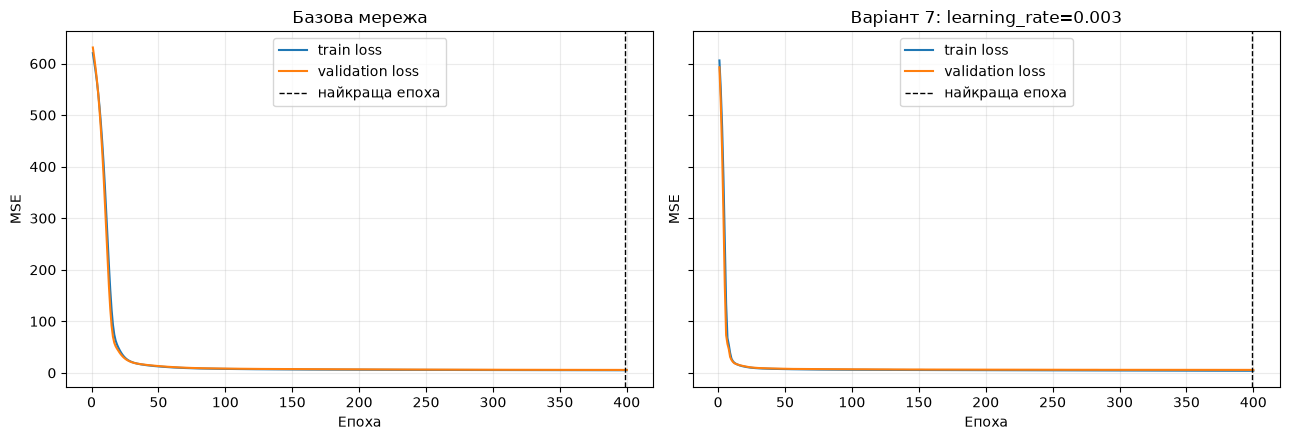

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, title, history in [
    (axes[0], "Базова мережа", baseline_history),
    (axes[1], "Варіант 7: learning_rate=0.003", variant_history),
]:
    epochs = np.arange(1, len(history.history["loss"]) + 1)
    ax.plot(epochs, history.history["loss"], label="train loss")
    ax.plot(epochs, history.history["val_loss"], label="validation loss")
    ax.axvline(np.argmin(history.history["val_loss"]) + 1,
               color="black", linestyle="--", linewidth=1,
               label="найкраща епоха")
    ax.set_title(title)
    ax.set_xlabel("Епоха")
    ax.set_ylabel("MSE")
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

## 5. Вибір за validation і одноразове оцінювання test

Рішення про найкращий алгоритм загалом і найкращу нейромережу приймається **до** перегляду test, за найменшим validation RMSE. Після фіксації рішення test оцінюється один раз для всіх чотирьох фінальних моделей.

In [9]:
neural_models = {
    "Baseline NN": baseline_best,
    "Variant 7 NN": variant_best,
}
neural_details = {
    "Baseline NN": baseline_details,
    "Variant 7 NN": variant_details,
}

val_rows = []
for name, model in classical_models.items():
    metrics = regression_metrics(y_val, model.predict(X_val_ready))
    val_rows.append({"model": name, "validation_MAE": metrics["MAE"],
                     "validation_RMSE": metrics["RMSE"], "validation_R2": metrics["R2"],
                     "epochs": np.nan, "best_epoch": np.nan})
for name, model in neural_models.items():
    pred = model.predict(X_val_ready, verbose=0).reshape(-1)
    metrics = regression_metrics(y_val, pred)
    val_rows.append({"model": name, "validation_MAE": metrics["MAE"],
                     "validation_RMSE": metrics["RMSE"], "validation_R2": metrics["R2"],
                     "epochs": neural_details[name]["epochs"],
                     "best_epoch": neural_details[name]["best_epoch"]})

validation_table = pd.DataFrame(val_rows).sort_values("validation_RMSE").reset_index(drop=True)
selected_overall_name = validation_table.loc[0, "model"]
selected_nn_name = (
    validation_table[validation_table["model"].isin(neural_models)]
    .sort_values("validation_RMSE").iloc[0]["model"]
)

display(validation_table.round(4))
print("РІШЕННЯ ДО TEST")
print("Найкращий алгоритм загалом за validation RMSE:", selected_overall_name)
print("Найкраща нейромережа за validation RMSE:", selected_nn_name)

,model,validation_MAE,validation_RMSE,validation_R2,epochs,best_epoch
0,Baseline NN,1.8106,2.3927,0.9228,400.0,399.0
1,Variant 7 NN,1.7547,2.3991,0.9224,400.0,399.0
2,LinearRegression,2.9013,3.6103,0.8242,NaN,NaN
3,DummyRegressor,7.3549,8.6119,-0.0000,NaN,NaN


РІШЕННЯ ДО TEST
Найкращий алгоритм загалом за validation RMSE: Baseline NN
Найкраща нейромережа за validation RMSE: Baseline NN


In [10]:
all_models = {**classical_models, **neural_models}
test_rows = []
test_predictions = {}

for name, model in all_models.items():
    if name in neural_models:
        pred = model.predict(X_test_ready, verbose=0).reshape(-1)
    else:
        pred = model.predict(X_test_ready).reshape(-1)
    test_predictions[name] = pred
    metrics = regression_metrics(y_test, pred)
    val_info = validation_table.loc[validation_table["model"] == name].iloc[0]
    test_rows.append({
        "model": name,
        "validation_RMSE": val_info["validation_RMSE"],
        "test_MAE": metrics["MAE"],
        "test_RMSE": metrics["RMSE"],
        "test_R2": metrics["R2"],
        "epochs": val_info["epochs"],
        "best_epoch": val_info["best_epoch"],
    })

results_table = pd.DataFrame(test_rows).sort_values("validation_RMSE").reset_index(drop=True)
display(results_table.round(4))
print("Вибір не змінюється після перегляду test.")

,model,validation_RMSE,test_MAE,test_RMSE,test_R2,epochs,best_epoch
0,Baseline NN,2.3927,1.7076,2.2836,0.9069,400.0,399.0
1,Variant 7 NN,2.3991,1.7575,2.4907,0.8893,400.0,399.0
2,LinearRegression,3.6103,2.4025,3.0580,0.8331,NaN,NaN
3,DummyRegressor,8.6119,6.0678,7.4882,-0.0005,NaN,NaN


Вибір не змінюється після перегляду test.


## 6. Аналіз помилок обраної нейромережі

Залишок визначено як $y_{true}-y_{pred}$. Додатний залишок означає, що модель занизила MPG; від'ємний — завищила.

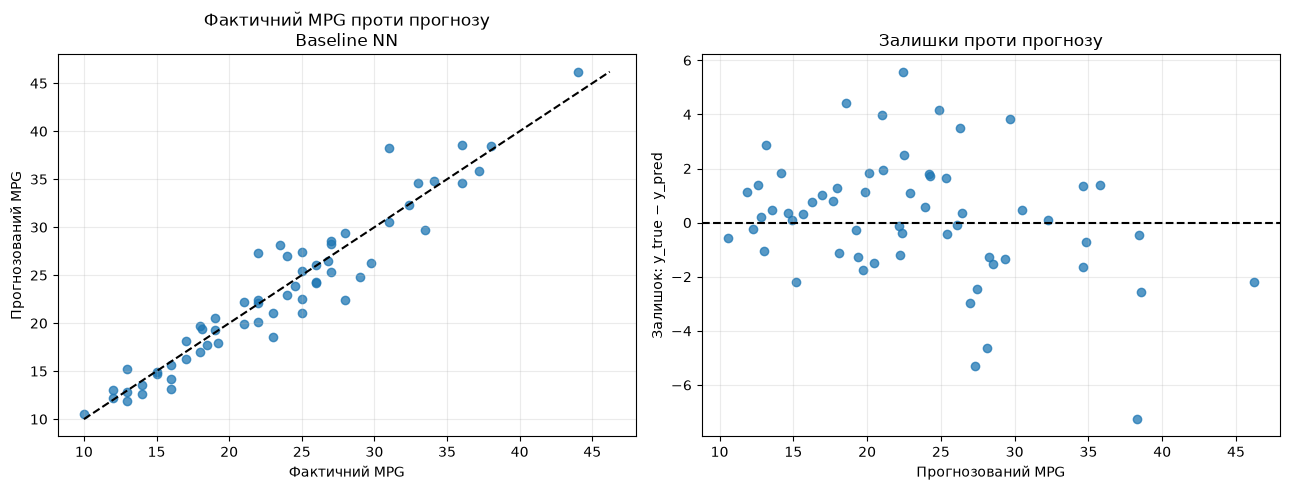

In [11]:
selected_nn = neural_models[selected_nn_name]
y_test_np = y_test.to_numpy()
selected_nn_pred = test_predictions[selected_nn_name]
residuals = y_test_np - selected_nn_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test_np, selected_nn_pred, alpha=0.75)
diag_min = min(y_test_np.min(), selected_nn_pred.min())
diag_max = max(y_test_np.max(), selected_nn_pred.max())
axes[0].plot([diag_min, diag_max], [diag_min, diag_max], "k--", linewidth=1.5)
axes[0].set_title(f"Фактичний MPG проти прогнозу\n{selected_nn_name}")
axes[0].set_xlabel("Фактичний MPG")
axes[0].set_ylabel("Прогнозований MPG")
axes[0].grid(alpha=0.25)

axes[1].scatter(selected_nn_pred, residuals, alpha=0.75)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1.5)
axes[1].set_title("Залишки проти прогнозу")
axes[1].set_xlabel("Прогнозований MPG")
axes[1].set_ylabel("Залишок: y_true − y_pred")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [12]:
error_analysis = X_test.copy()
error_analysis.insert(0, "car_name", df.loc[X_test.index, "car_name"])
error_analysis["actual_mpg"] = y_test_np
error_analysis["predicted_mpg"] = selected_nn_pred
error_analysis["residual"] = residuals
error_analysis["absolute_error"] = np.abs(residuals)

top5_errors = error_analysis.nlargest(5, "absolute_error").copy()

def possible_explanation(row):
    notes = []
    if row["weight"] >= X_test["weight"].quantile(0.85):
        notes.append("велика маса")
    if row["horsepower"] >= X_test["horsepower"].quantile(0.85):
        notes.append("висока потужність")
    if row["model_year"] in (X_test["model_year"].min(), X_test["model_year"].max()):
        notes.append("крайній модельний рік")
    if row["origin"] in X_test["origin"].value_counts().nsmallest(1).index:
        notes.append("рідше представлена категорія origin")
    return ", ".join(notes) if notes else "нетипове поєднання ознак або невраховані характеристики авто"

top5_errors["можливе_пояснення"] = top5_errors.apply(possible_explanation, axis=1)
display(top5_errors.round(3))
print(
    "Пояснення є гіпотезами для подальшої перевірки, а не доказом причинного впливу. "
    "Об'єкти з test не видаляються."
)

,car_name,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,actual_mpg,predicted_mpg,residual,absolute_error,можливе_пояснення
377,mazda glc custom,4,91.0,68.0,1970.0,17.6,82,3,31.0,38.262001,-7.262,7.262,"крайній модельний рік, рідше представлена кате..."
30,chevrolet vega 2300,4,140.0,90.0,2264.0,15.5,71,1,28.0,22.423000,5.577,5.577,нетипове поєднання ознак або невраховані харак...
389,ford granada l,6,232.0,112.0,2835.0,14.7,82,1,22.0,27.294001,-5.294,5.294,крайній модельний рік
341,chevrolet citation,6,173.0,110.0,2725.0,12.6,81,1,23.5,28.129000,-4.629,4.629,нетипове поєднання ознак або невраховані харак...
298,cadillac eldorado,8,350.0,125.0,3900.0,17.4,79,1,23.0,18.582001,4.418,4.418,нетипове поєднання ознак або невраховані харак...


Пояснення є гіпотезами для подальшої перевірки, а не доказом причинного впливу. Об'єкти з test не видаляються.


## 7. Збереження та перевірка відновлення

Зберігаються обрана за validation нейромережа, навчений `ColumnTransformer`, метадані та таблиця результатів. Якщо найкращою загалом є класична модель, вона також зберігається. Для трьох сирих рядків після завантаження використовується лише `transform`, без `fit_transform` або `adapt`.

In [13]:
model_path = output_dir / "lab6_model.keras"
preprocessor_path = output_dir / "preprocessor.joblib"
metadata_path = output_dir / "metadata.json"
results_path = output_dir / "validation_test_results.csv"

selected_nn.save(model_path)
joblib.dump(preprocessor, preprocessor_path)
results_table.to_csv(results_path, index=False)

classic_model_path = None
if selected_overall_name in classical_models:
    classic_model_path = output_dir / "lab6_classic_model.joblib"
    joblib.dump(classical_models[selected_overall_name], classic_model_path)

metadata = {
    "student": "Люлько Станіслав",
    "student_number": STUDENT_NUMBER,
    "variant": VARIANT,
    "variant_change": "learning_rate=0.003",
    "seed": SEED,
    "target": {"name": "mpg", "units": "miles per gallon"},
    "raw_feature_columns": X.columns.tolist(),
    "prepared_feature_names": feature_names,
    "split_indices": {
        "train": [int(i) for i in X_train.index],
        "validation": [int(i) for i in X_val.index],
        "test": [int(i) for i in X_test.index],
    },
    "selected_overall_by_validation_rmse": selected_overall_name,
    "selected_neural_network_by_validation_rmse": selected_nn_name,
    "versions": versions,
    "dataset": {
        "name": "UCI Auto MPG",
        "doi": "10.24432/C5859H",
        "url": "https://archive.ics.uci.edu/dataset/9/auto+mpg",
        "license": "CC BY 4.0",
        "local_file": data_path.name,
    },
}
metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")

loaded_model = keras.models.load_model(model_path)
loaded_preprocessor = joblib.load(preprocessor_path)  # лише з довіреного локального джерела
raw_three = X_test.iloc[:3].copy()
ready_three = loaded_preprocessor.transform(raw_three).astype(np.float32)
pred_before = selected_nn.predict(X_test_ready[:3], verbose=0)
pred_after = loaded_model.predict(ready_three, verbose=0)
np.testing.assert_allclose(pred_before, pred_after, rtol=1e-5, atol=1e-6)

print("Збережено:", model_path.name, preprocessor_path.name,
      metadata_path.name, results_path.name)
if classic_model_path is not None:
    print("Збережено найкращу класичну модель:", classic_model_path.name)
print("Перевірку відновлення пройдено: прогнози для 3 сирих рядків збігаються.")
display(pd.DataFrame({
    "prediction_before_save": pred_before.reshape(-1),
    "prediction_after_load": pred_after.reshape(-1),
}, index=raw_three.index).round(6))

Збережено: lab6_model.keras preprocessor.joblib metadata.json validation_test_results.csv
Перевірку відновлення пройдено: прогнози для 3 сирих рядків збігаються.


,prediction_before_save,prediction_after_load
198,34.648605,34.648605
396,29.347578,29.347578
33,20.500723,20.500723


## 8. Відповіді на запитання для самоперевірки

1. **Що нового додає ця робота?** Роботу з реальними табличними даними, імпутацію, кодування категорій, контроль витоку, класичні baseline-моделі, checkpoint, аналіз помилок і збереження всього конвеєра.
2. **Чому `origin` кодують як категорію?** Його числа є кодами регіонів без природного порядку та відстані між значеннями.
3. **На яких даних навчають імпутер і `Normalization`?** Виключно на train; validation і test лише трансформуються.
4. **Для чого потрібні `DummyRegressor` і `LinearRegression`?** Вони задають прості точки порівняння й показують, чи виправдовує нейромережа додаткову складність.
5. **`Normalization` і `BatchNormalization`.** `Normalization` використовує наперед адаптовані статистики ознак; `BatchNormalization` нормалізує внутрішні активації за mini-batch під час навчання й має навчувані параметри.
6. **`EarlyStopping` і `ModelCheckpoint`.** Перший зупиняє навчання після відсутності покращення, другий записує найкращу модель на диск.
7. **Чому останні ваги не обов'язково найкращі?** Після мінімуму validation loss навчання може тривати ще `patience` епох, а якість погіршитися.
8. **Чому модель обирають за validation?** Test має залишатися незалежною одноразовою оцінкою узагальнення; вибір за test спричиняє витік інформації.
9. **Що означає додатний залишок?** Фактичний MPG більший за прогноз, тобто модель занизила значення. Великі помилки досліджують разом із сирими ознаками й контекстом об'єктів.
10. **Чому одного `.keras` недостатньо?** Модель очікує вже імпутовані та закодовані ознаки у фіксованому порядку, тому для сирих рядків потрібні `preprocessor.joblib` і схема ознак.

## 9. Висновок

In [14]:
best_val_rmse = float(validation_table.iloc[0]["validation_RMSE"])
baseline_val_rmse = float(validation_table.loc[
    validation_table["model"] == "Baseline NN", "validation_RMSE"
].iloc[0])
variant_val_rmse = float(validation_table.loc[
    validation_table["model"] == "Variant 7 NN", "validation_RMSE"
].iloc[0])

conclusion = (
    f"У роботі побудовано єдиний безвитоковий конвеєр підготовки Auto MPG та порівняно "
    f"чотири регресійні моделі. За validation RMSE найкращою загалом стала "
    f"{selected_overall_name} (RMSE={best_val_rmse:.3f}), а серед нейромереж — "
    f"{selected_nn_name}. Збільшення learning rate з 0.001 до 0.003 змінило validation RMSE "
    f"з {baseline_val_rmse:.3f} до {variant_val_rmse:.3f}, тому складніша процедура навчання "
    f"оцінюється лише відносно фактичного результату, а не припущення про перевагу мережі. "
    f"Вибір за validation було зафіксовано до одноразового перегляду test. Експеримент обмежений "
    f"малим історичним набором даних, одним поділом і відсутніми характеристиками автомобілів, "
    f"тому він не доводить причинного впливу ознак і не підтверджує придатність моделі для сучасного автопарку."
)
print(conclusion)

У роботі побудовано єдиний безвитоковий конвеєр підготовки Auto MPG та порівняно чотири регресійні моделі. За validation RMSE найкращою загалом стала Baseline NN (RMSE=2.393), а серед нейромереж — Baseline NN. Збільшення learning rate з 0.001 до 0.003 змінило validation RMSE з 2.393 до 2.399, тому складніша процедура навчання оцінюється лише відносно фактичного результату, а не припущення про перевагу мережі. Вибір за validation було зафіксовано до одноразового перегляду test. Експеримент обмежений малим історичним набором даних, одним поділом і відсутніми характеристиками автомобілів, тому він не доводить причинного впливу ознак і не підтверджує придатність моделі для сучасного автопарку.
